# Fractional Brownian permeability and poroelastic material fields

In [1]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# Generator code used by this notebook: GaussianRandomFieldCircEmbed, PrefbmCov,
# FBmGenerator and compute_c are adapted from Binhao Li's FlowSimulation:
# https://github.com/lastoor/FlowSimulation/blob/4afc232100a16e8c6e636a534da732c5d126f947/simulation/grf_generation.py
# The generator is described by Li, de Barros & Sahimi (2026), https://doi.org/10.1029/2026GL124085,
# and uses the fractional Brownian field construction of Stein (2002), https://doi.org/10.1198/106186002466.
# Material laws: normalized Kozeny–Carman permeability–porosity relation (Carman, 1937, reprint: https://doi.org/10.1016/S0263-8762(97)80003-2)
# and the two-regime elastic law adapted from Osorio et al. (2025), Eq. (3), with study-specific parameters:
# https://doi.org/10.1029/2024JB030836

from pathlib import Path
import sys

import numpy as np
import pandas
from IPython.display import display, Image

root = Path.cwd()
source = root / "src" / "material_sim"
if not (source / "base/fbm500_biot_core.py").is_file():
    raise FileNotFoundError("Open this notebook in the extracted release folder.")
sys.path.insert(0, str(source / "base"))
import fbm500_biot_core as b
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

out = root / "outputs" / "material_sim"
out.mkdir(parents=True, exist_ok=True)
material_file = out / "real_027_material.npz"

Matplotlib is building the font cache; this may take a moment.


In [2]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

SEED0, MEMBER_ID, NX, NY = 42, 27, 100, 100
idx = MEMBER_ID - 1
seed = SEED0 + idx
b.K_REF_MD = 1.0
print(f"Injection case 001 | original realization {MEMBER_ID:03d} | seed {seed} | retained in the 443-member EA")

Injection case 001 | original realization 027 | seed 68 | retained in the 443-member EA


In [3]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

from fbm500_biot_core import target_standardize

np.random.seed(SEED0+idx)
gen=b.FBmGenerator(c=b.compute_c(500,.5,1.0),alpha=1.0,num_pt=500,minpadding=0)
logk=target_standardize(gen.sample(),2.0)
coeff=b.material_from_logk(logk,NX,NY)

In [4]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

np.savez_compressed(material_file, **coeff, seed=np.int64(seed), realization=np.int64(MEMBER_ID),
                    fbm_H=np.float64(.5), k_ref_md=np.float64(b.K_REF_MD),
                    fine_logk_mean=logk.mean(), fine_logk_std=logk.std(ddof=0),
                    fine_shape=np.array(logk.shape))
print(f"Wrote {material_file.relative_to(root)}")
display(pandas.DataFrame([
    {"grid": "fBm", "shape": str(logk.shape), "mean ln(k/kref)": logk.mean(), "std ln(k/kref)": logk.std()},
    {"grid": "finite elements", "shape":str(coeff["logk"].shape), "mean ln(k/kref)":coeff["logk"].mean(), "std ln(k/kref)":coeff["logk"].std()}
]).set_index("grid"))

Wrote outputs/material_sim/real_027_material.npz


,shape,mean ln(k/kref),std ln(k/kref)
grid,,,
fBm,"(500, 500)",-4.365575e-17,2.000000
finite elements,"(100, 100)",-6.821210e-17,1.988368


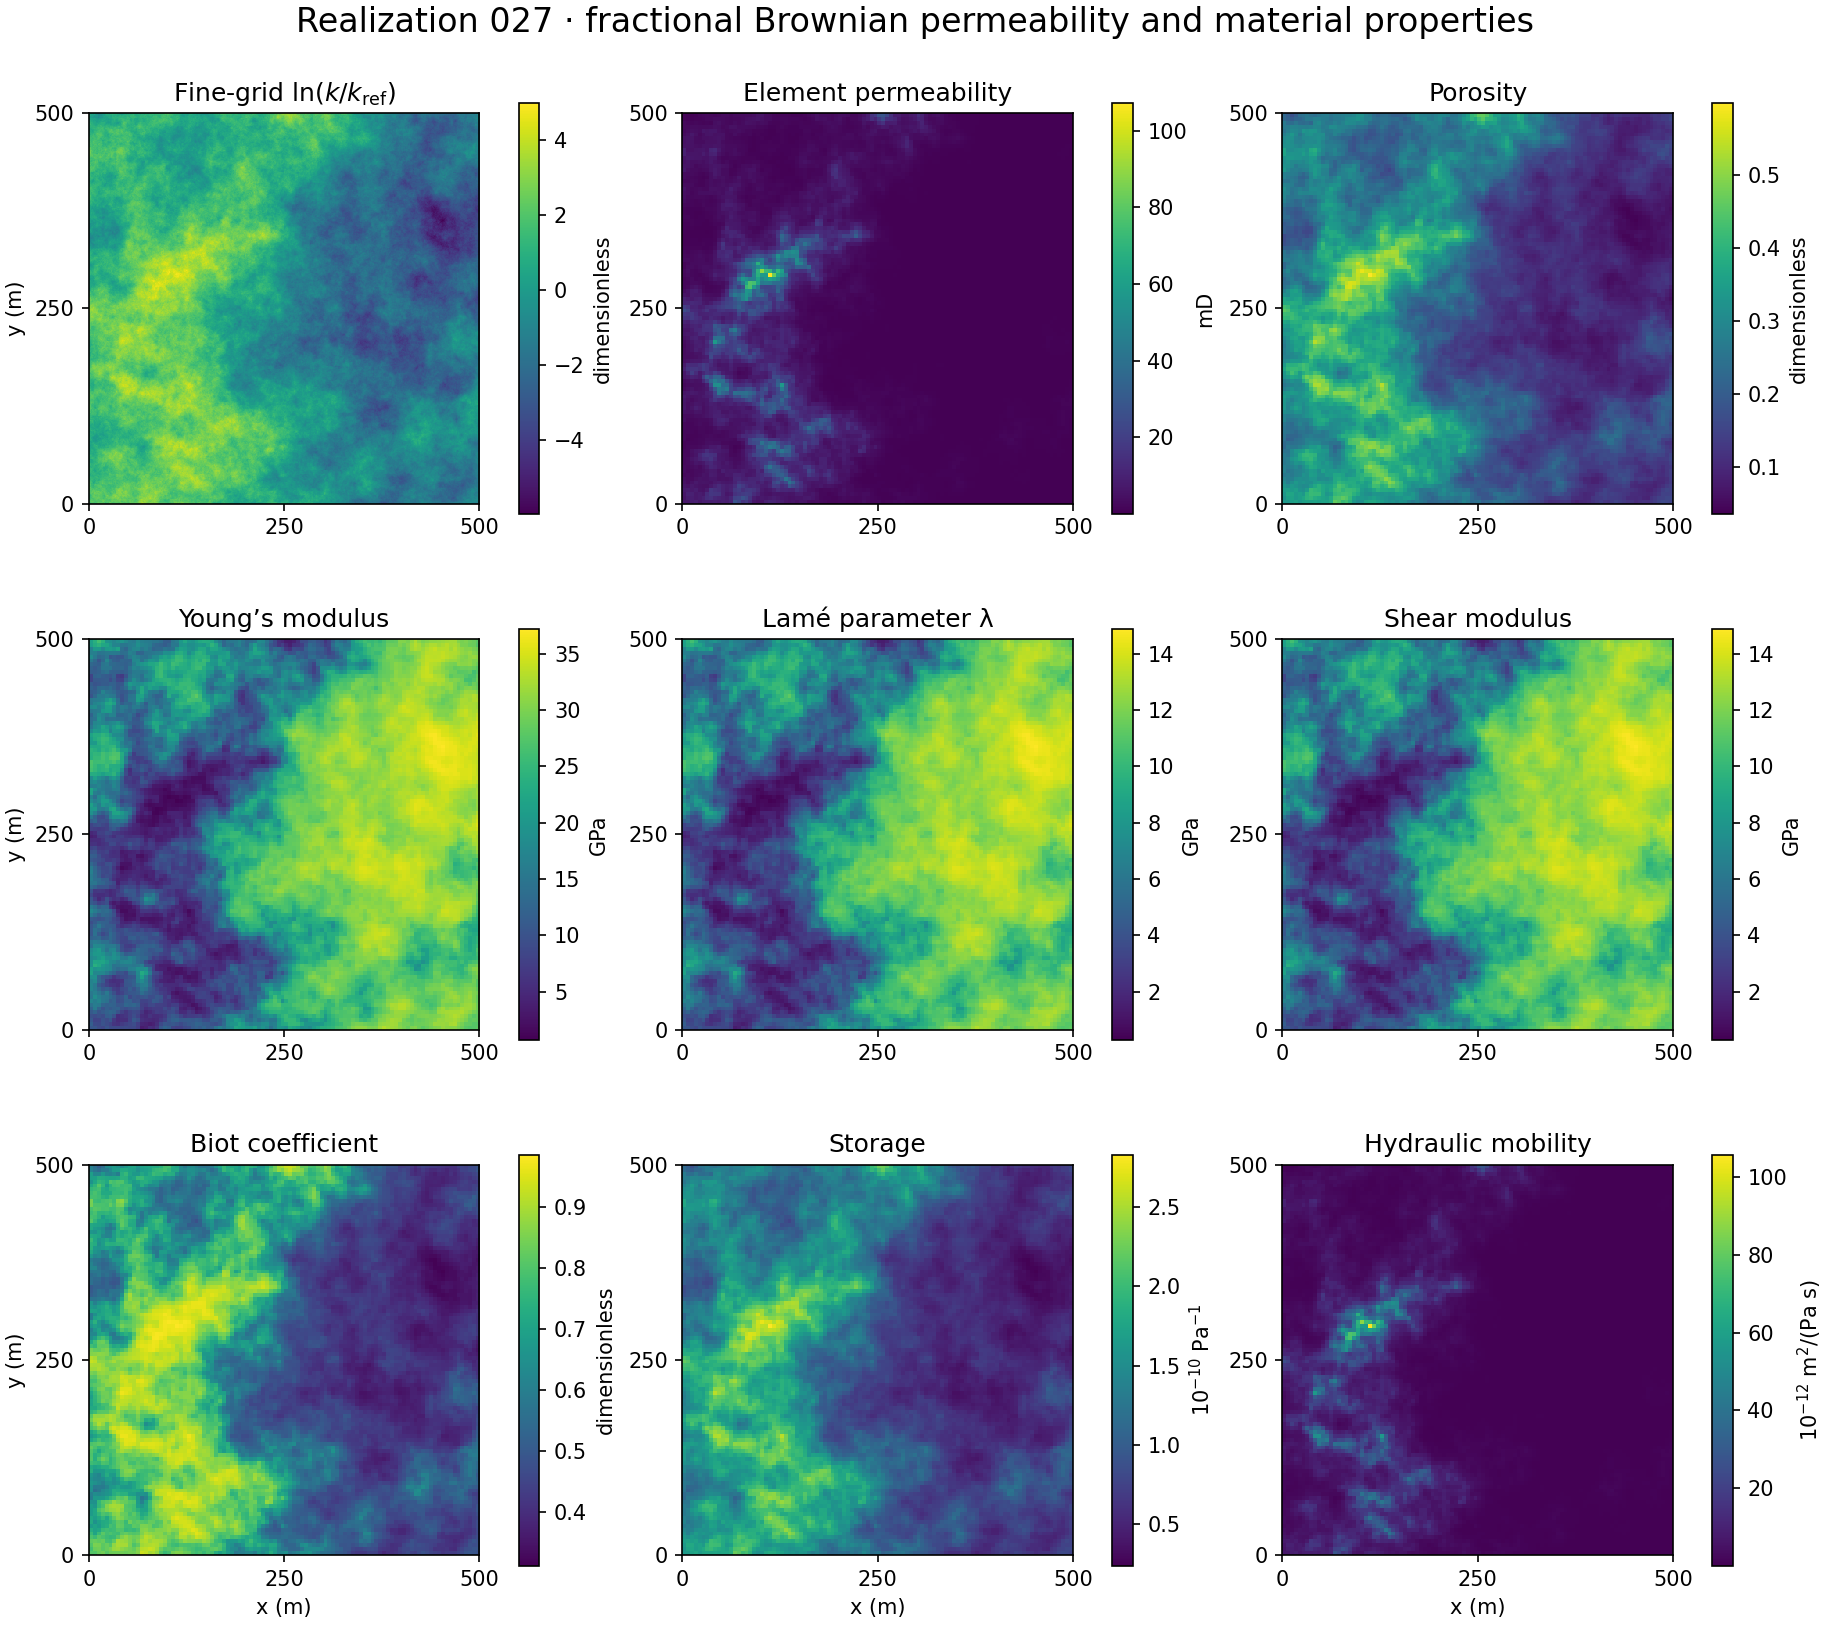

In [5]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

panels = [
    (logk, r"Fine-grid $\ln(k/k_{\rm ref})$", "dimensionless"),
    (coeff["kmd"], "Element permeability", "mD"), (coeff["phi"], "Porosity", "dimensionless"),
    (coeff["E"]/1e9, "Young’s modulus", "GPa"), (coeff["lam"]/1e9, "Lamé parameter λ", "GPa"),
    (coeff["G"]/1e9, "Shear modulus", "GPa"), (coeff["alpha_mech"], "Biot coefficient", "dimensionless"),
    (coeff["S"]*1e10, "Storage", r"$10^{-10}$ Pa$^{-1}$"),
    (coeff["mobility"]*1e12, "Hydraulic mobility", r"$10^{-12}$ m$^2$/(Pa s)"),
]
fig, axes = plt.subplots(3, 3, figsize=(12.2, 11), constrained_layout=True)
for ax, (arr, label, unit) in zip(axes.flat, panels):
    mesh = ax.imshow(arr, extent=(0,500,0,500), origin="lower", interpolation="nearest", cmap="viridis")
    ax.set(title=label, xticks=[0,250,500], yticks=[0,250,500])
    fig.colorbar(mesh, ax=ax, shrink=.8, label=unit)
for ax in axes[-1]: ax.set_xlabel("x (m)")
for ax in axes[:,0]: ax.set_ylabel("y (m)")
fig.suptitle("Realization 027 · fractional Brownian permeability and material properties", fontsize=16)
fig_path = out / "real_027_material_fields.png"
fig.savefig(fig_path, dpi=150, facecolor="white")
plt.close(fig)
display(Image(filename=str(fig_path), width=1000))